### Analisis 03 del E-Commerce Business Analysis

In [ ]:
# Library
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
import scipy.stats
from sklearn.metrics import mean_squared_error
from math import sqrt
import os
from os import listdir
from datetime import datetime
import pandas as pd
from matplotlib.dates import DateFormatter
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import seaborn as sn
import plotly.express as px
import kagglehub
import seaborn as sns
print("listo listo")

listo ok


d:\Josefina\Proyectos\Datascience\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# El link se obtiene de kagglenjmmmmmmmmmmmmmmbnn                                                                                                    v
df = pd.read_csv("C:/Users/Josefina Urquiza/.cache/kagglehub/datasets/umuttuygurr/e-commerce-customer-behavior-and-sales-analysis-tr/versions/2/ecommerce_customer_behavior_dataset_v2.csv")

df

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17044,ORD_004999-1,CUST_04999,2024-01-16,44,Male,Antalya,Beauty,68.65,2,0.00,137.30,Digital Wallet,Mobile,14,10,False,6,1
17045,ORD_005000-1,CUST_05000,2023-02-22,24,Female,Eskisehir,Beauty,156.12,1,0.00,156.12,Credit Card,Mobile,15,8,True,7,5
17046,ORD_005000-2,CUST_05000,2023-06-29,24,Female,Eskisehir,Home & Garden,1065.24,3,0.00,3195.72,Credit Card,Desktop,17,11,True,5,4
17047,ORD_005000-3,CUST_05000,2023-12-29,24,Female,Eskisehir,Books,47.73,2,8.80,86.66,Credit Card,Desktop,13,11,True,12,2


####  01. Definicion previa del problema: 

El objetivo de este análisis es identificar los factores que influyen tanto en la recompra como en la facturación por compra, con el fin de comprender qué variables impulsan la rentabilidad del negocio.

A través del análisis de variables demográficas, de comportamiento de compra, comportamiento digital y experiencia post-compra, se buscará determinar qué características están asociadas a:

- Mayor probabilidad de volver a c.
- Mayor nivel de facturación por compra (Total_Amount).

Este conocimiento permitirá orientar decisiones comerciales, optimizar estrategias de retención y maximizar el valor generado por cada cliente.

En esta notebook se analizarán los factores asociados al nivel de facturación por compra (Total_Amount), con el objetivo de identificar qué variables impulsan mayores ingresos y, por lo tanto, mayor rentabilidad del negocio.

Se evaluarán variables demográficas, de comportamiento de compra, digitales y de experiencia post-compra para detectar patrones asociados a tickets más altos.

## Entender la variable objetivo

In [ ]:
#Distribución y asimetría
#La pregunta ahora no es “cómo es la distribución”, sino si la facturación está concentrada en pocas órdenes?
print(df["Total_Amount"].describe())
print(df["Total_Amount"].skew())

count    17049.000000
mean      1277.438711
std       2358.436375
min          6.210000
25%        172.970000
50%        455.850000
75%       1267.750000
max      37852.050000
Name: Total_Amount, dtype: float64
4.584841564259209


Resumen
- La media es casi 3 veces más alta que la mediana.
- La mayoría de las órdenes son relativamente bajas
- Pero hay algunas órdenes MUY grandes que empujan la media hacia arriba
- Esto sugiere concentración del ingreso.
- La sd es nyt alta (casi el doble de la media), indica mucha variabilidad entre los montos
- Quartiles: El 50% de las órdenes facturan menos de 456, el 25% más alto empieza recién en 1268. Pero el máximo es 37.852
- skewness es muy alto, fuerte asimetria
- Distribución fuertemente sesgada a la derecha, lo que indica pocas órdenes de muy alto valor.
- No todas las órdenes importan igual

In [16]:
# Cuanto concentran las ordenes mas grandes
# Pregunta a responder: El 10% de órdenes explica qué porcentaje del ingreso?

print(df["Total_Amount"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))


# Calcular percentil 90
p90 = df["Total_Amount"].quantile(0.9)

# Filtrar top 10%
top_10 = df[df["Total_Amount"] >= p90]

# Calcular proporción del ingreso total
top_10_revenue_share = top_10["Total_Amount"].sum() / df["Total_Amount"].sum()

print("Proporción del ingreso generado por el Top 10%:", round(top_10_revenue_share * 100, 2), "%")

0.50      455.850
0.75     1267.750
0.90     3268.658
0.95     5323.470
0.99    12147.926
Name: Total_Amount, dtype: float64
Proporción del ingreso generado por el Top 10%: 53.41 %


In [ ]:
df["High_Value_Order"] = (df["Total_Amount"] >= p90).astype(int)

df["High_Value_Order"].value_counts()
# 0 → órdenes normales
# 1 → órdenes de alto valor

High_Value_Order
0    15344
1     1705
Name: count, dtype: int64

In [ ]:
# Perfil de órdenes de alto valor, 
# Comparar variables numéricas
# Esto dice qué caracteriza a las órdenes más rentables
df.groupby("High_Value_Order")[[
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Session_Duration_Minutes",
    "Pages_Viewed",
    "Delivery_Time_Days",
    "Customer_Rating"
]].mean()

,Unit_Price,Quantity,Discount_Amount,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating
High_Value_Order,,,,,,,
0,276.199117,2.912735,39.129807,14.542753,8.999348,6.522550,3.896181
1,1993.124129,3.899120,345.695109,14.471554,9.036950,6.333138,3.928446


In [23]:
# Perfil por categoría
print(pd.crosstab(df["Product_Category"], df["High_Value_Order"], normalize="index"))

print("----------------------------------------------------")
#O por ticket promedio
print(df.groupby("Product_Category")["Total_Amount"].mean().sort_values(ascending=False))

High_Value_Order         0         1
Product_Category                    
Beauty            1.000000  0.000000
Books             1.000000  0.000000
Electronics       0.460945  0.539055
Fashion           0.988813  0.011187
Food              1.000000  0.000000
Home & Garden     0.826214  0.173786
Sports            0.909253  0.090747
Toys              0.999043  0.000957
----------------------------------------------------
Product_Category
Electronics      5053.952580
Home & Garden    1953.351427
Sports           1425.750440
Fashion           767.040710
Toys              485.281115
Beauty            313.940787
Food              200.691702
Books             163.372217
Name: Total_Amount, dtype: float64


In [24]:
# Device vs Ticket
df.groupby("Device_Type")["Total_Amount"].mean().sort_values(ascending=False)

Device_Type
Desktop    1310.767677
Mobile     1260.472104
Tablet     1257.634094
Name: Total_Amount, dtype: float64

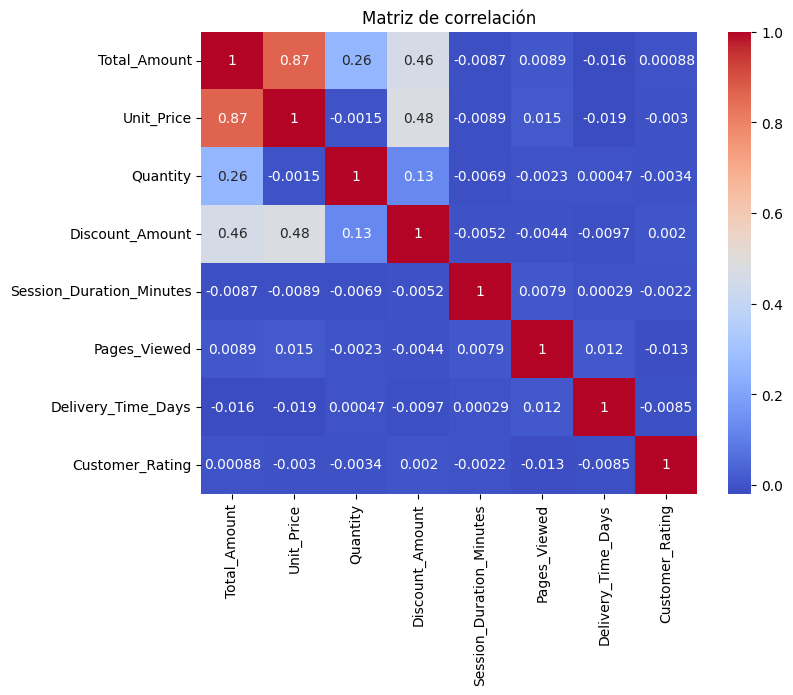

In [ ]:
#Correlacion generla

plt.figure(figsize=(8,6))
sns.heatmap(
    df[[
        "Total_Amount",
        "Unit_Price",
        "Quantity",
        "Discount_Amount",
        "Session_Duration_Minutes",
        "Pages_Viewed",
        "Delivery_Time_Days",
        "Customer_Rating"
    ]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Matriz de correlación")
plt.show()

In [26]:
# Como es asimetrica la distribucion probamos hacer una regresion lineal con log-transform

df["Log_Total"] = np.log1p(df["Total_Amount"])

#Variables de interes
X = df[[
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Session_Duration_Minutes",
    "Pages_Viewed",
    "Delivery_Time_Days",
    "Customer_Rating"
]]

y = df["Log_Total"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# modelo
model = LinearRegression()
model.fit(X_scaled, y)

coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": model.coef_
})

coef_df.sort_values(by="Coeficiente", ascending=False)

,Variable,Coeficiente
0,Unit_Price,1.015887
1,Quantity,0.552697
6,Customer_Rating,0.008326
5,Delivery_Time_Days,0.000734
4,Pages_Viewed,-0.008584
3,Session_Duration_Minutes,-0.011658
2,Discount_Amount,-0.049705
